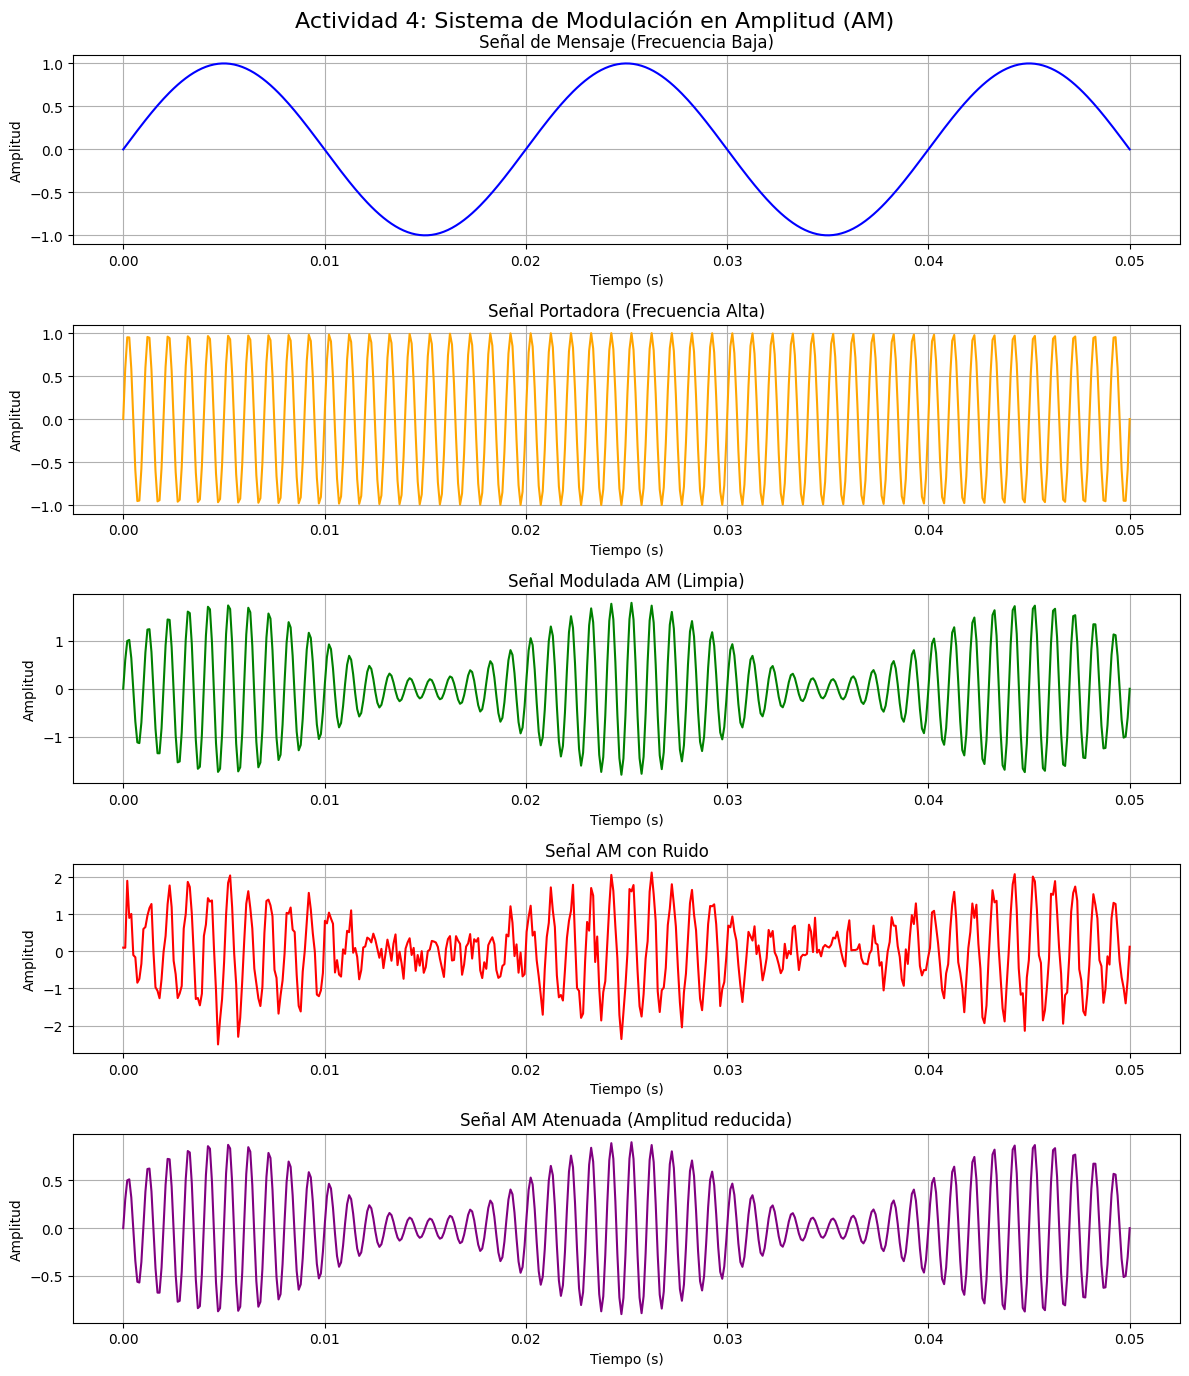

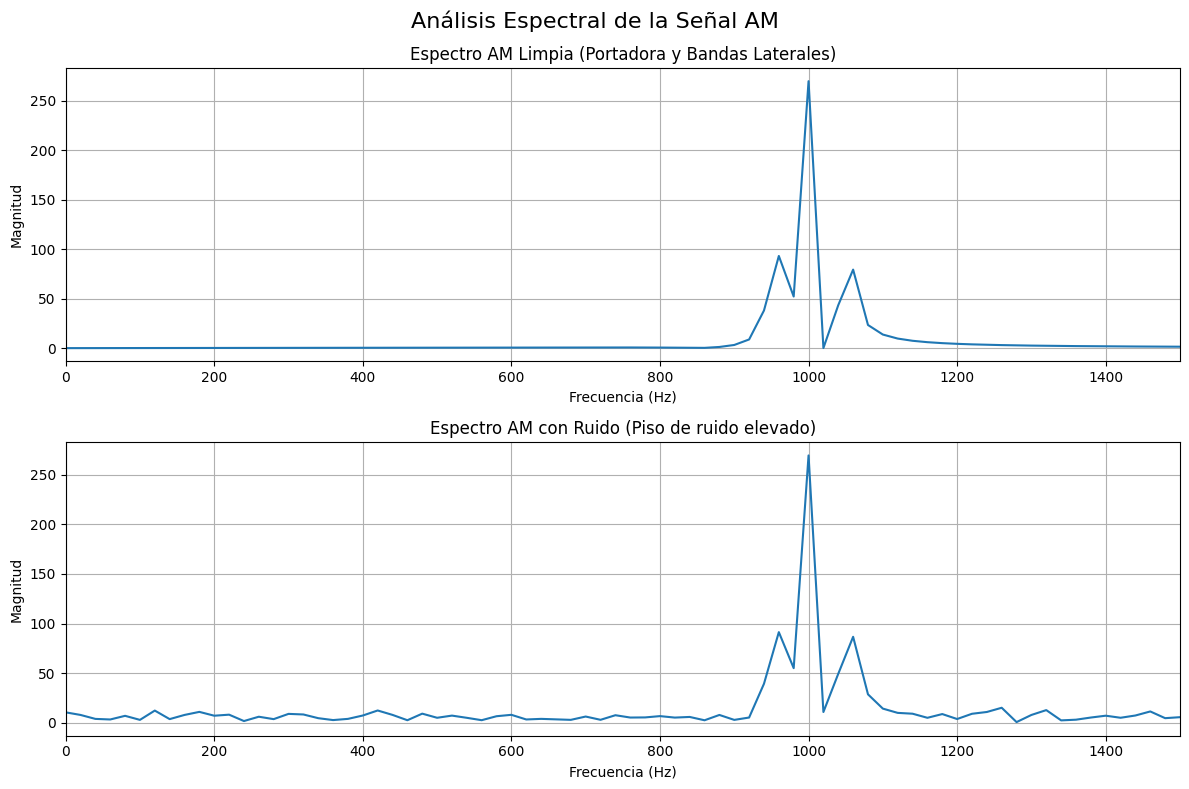

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. DEFINICIÓN DE PARÁMETROS Y SEÑALES ---
fs = 10000  # Frecuencia de muestreo
t = np.linspace(0, 0.05, int(fs * 0.05)) # 50 ms de duración

# Señal de mensaje (Información) - Frecuencia baja (50 Hz)
fm = 50
mensaje = np.sin(2 * np.pi * fm * t)

# Señal Portadora - Frecuencia alta (1000 Hz)
fc = 1000
portadora = np.sin(2 * np.pi * fc * t)

# --- 2. IMPLEMENTACIÓN DE LA MODULACIÓN AM ---
# Índice de modulación (m = 1 para AM al 100%)
m = 0.8
# Ecuación AM: s(t) = Ac * [1 + m*x(t)] * cos(2*pi*fc*t)
# Usamos Ac = 1
senal_am = (1 + m * mensaje) * portadora

# --- 3. CONDICIONES: RUIDO Y ATENUACIÓN ---
# Ruido blanco gaussiano
ruido = np.random.normal(0, 0.3, len(t))
senal_am_ruidosa = senal_am + ruido

# Atenuación (reducir la amplitud a la mitad)
atenuacion = 0.5
senal_am_atenuada = senal_am * atenuacion

# --- 4. VISUALIZACIÓN EN EL DOMINIO DEL TIEMPO ---
fig, axs = plt.subplots(5, 1, figsize=(12, 14))
fig.suptitle('Actividad 4: Sistema de Modulación en Amplitud (AM)', fontsize=16)

axs[0].plot(t, mensaje, color='blue'); axs[0].set_title('Señal de Mensaje (Frecuencia Baja)')
axs[1].plot(t, portadora, color='orange'); axs[1].set_title('Señal Portadora (Frecuencia Alta)')
axs[2].plot(t, senal_am, color='green'); axs[2].set_title('Señal Modulada AM (Limpia)')
axs[3].plot(t, senal_am_ruidosa, color='red'); axs[3].set_title('Señal AM con Ruido')
axs[4].plot(t, senal_am_atenuada, color='purple'); axs[4].set_title('Señal AM Atenuada (Amplitud reducida)')

for ax in axs:
    ax.set_xlabel('Tiempo (s)'); ax.set_ylabel('Amplitud'); ax.grid(True)
plt.tight_layout()
plt.show()

# --- 5. ANÁLISIS EN EL DOMINIO DE LA FRECUENCIA (FFT) ---
def plot_espectro(senal, titulo, ax):
    N = len(senal)
    fft_senal = np.fft.fft(senal)
    freqs = np.fft.fftfreq(N, 1/fs)
    # Solo la mitad positiva
    ax.plot(freqs[:N//2], np.abs(fft_senal[:N//2]))
    ax.set_title(titulo); ax.set_xlabel('Frecuencia (Hz)'); ax.set_ylabel('Magnitud')
    ax.set_xlim(0, 1500); ax.grid()

fig2, axs2 = plt.subplots(2, 1, figsize=(12, 8))
fig2.suptitle('Análisis Espectral de la Señal AM', fontsize=16)
plot_espectro(senal_am, 'Espectro AM Limpia (Portadora y Bandas Laterales)', axs2[0])
plot_espectro(senal_am_ruidosa, 'Espectro AM con Ruido (Piso de ruido elevado)', axs2[1])
plt.tight_layout()
plt.show()